# AI-Based Handwritten Digit Generation Using GANs
Project Objective

Build a Generative Adversarial Network (GAN) using TensorFlow/Keras to generate handwritten digit images similar to the MNIST dataset. The project includes:

Data preprocessing

Generator implementation

Discriminator implementation

GAN training

Image generation

Loss curve visualization

Analysis and conclusion

## Step 1: Import Required Libraries

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


## Step 2: Load and Preprocess MNIST Dataset


In [ ]:
# Load dataset

(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

print("Original Shape:", x_train.shape)

# Normalize to [-1,1]

x_train = (x_train.astype('float32') - 127.5) / 127.5

# Reshape

x_train = x_train.reshape(
    x_train.shape[0],
    28,
    28,
    1
)

print("Processed Shape:", x_train.shape)
print("Min Value:", x_train.min())
print("Max Value:", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Original Shape: (60000, 28, 28)
Processed Shape: (60000, 28, 28, 1)
Min Value: -1.0
Max Value: 1.0


## Step 3: Visualize Sample Images

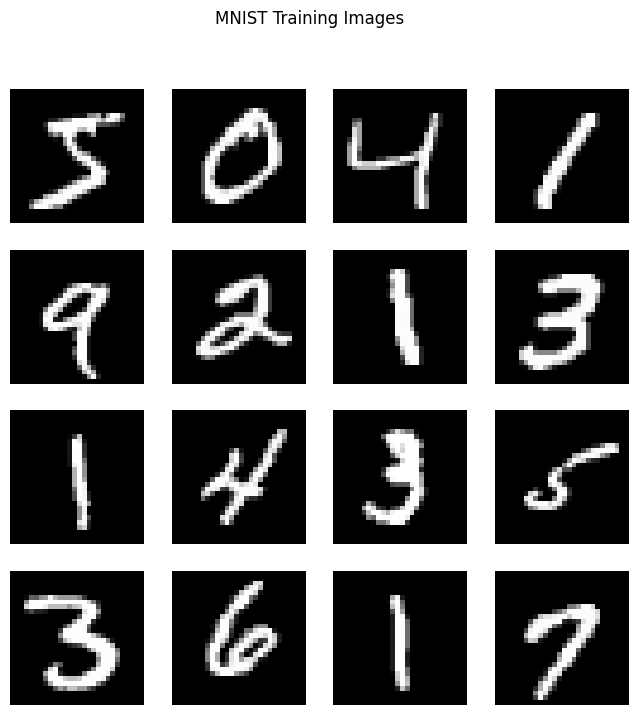

In [ ]:
plt.figure(figsize=(8,8))

for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(x_train[i].reshape(28,28), cmap='gray')
    plt.axis('off')

plt.suptitle("MNIST Training Images")
plt.show()

## Step 4: Define Generator Network

Architecture required:

Dense

BatchNormalization

LeakyReLU

Conv2DTranspose

Output with Tanh

In [ ]:
def build_generator():

    model = tf.keras.Sequential()

    model.add(layers.Dense(
        7*7*256,
        use_bias=False,
        input_shape=(100,)
    ))

    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Reshape((7,7,256)))

    model.add(layers.Conv2DTranspose(
        128,
        (5,5),
        strides=(1,1),
        padding='same',
        use_bias=False
    ))

    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(
        64,
        (5,5),
        strides=(2,2),
        padding='same',
        use_bias=False
    ))

    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(
        1,
        (5,5),
        strides=(2,2),
        padding='same',
        use_bias=False,
        activation='tanh'
    ))

    return model

generator = build_generator()

generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

## Step 5: Test Generator

(1, 28, 28, 1)


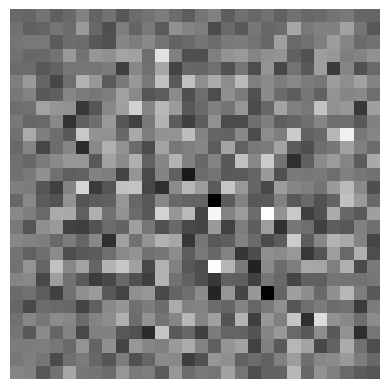

In [ ]:
noise = tf.random.normal([1,100])

generated_image = generator(noise, training=False)

print(generated_image.shape)

plt.imshow(generated_image[0,:,:,0], cmap='gray')
plt.axis('off')
plt.show()

## Step 6: Define Discriminator Network

Architecture required:

Conv2D

LeakyReLU

Dropout

Flatten

Dense Sigmoid

In [ ]:
def build_discriminator():

    model = tf.keras.Sequential()

    model.add(layers.Conv2D(
        64,
        (5,5),
        strides=(2,2),
        padding='same',
        input_shape=[28,28,1]
    ))

    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(
        128,
        (5,5),
        strides=(2,2),
        padding='same'
    ))

    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())

    model.add(layers.Dense(
        1,
        activation='sigmoid'
    ))

    return model

discriminator = build_discriminator()

discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

## Step 7: Define Loss Functions

Assignment requires Binary Cross Entropy.

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy()

def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss


def generator_loss(fake_output):

    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

## Step 8: Define Optimizers

Required:

Adam
learning_rate = 0.0002
beta_1 = 0.5

In [ ]:
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

## Step 9: Create Dataset Pipeline

In [ ]:
BUFFER_SIZE = 60000
BATCH_SIZE = 256

train_dataset = tf.data.Dataset.from_tensor_slices(
    x_train
).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

## Step 10: Define Training Step

In [ ]:
noise_dim = 100

@tf.function

def train_step(images):

    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape,\
         tf.GradientTape() as disc_tape:

        generated_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            images,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    gradients_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gradients_generator,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            gradients_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss

## Step 11: Generate Image Samples

In [ ]:
seed = tf.random.normal([16,100])

def generate_and_save_images(model, epoch, test_input):

    predictions = model(
        test_input,
        training=False
    )

    fig = plt.figure(figsize=(4,4))

    for i in range(predictions.shape[0]):

        plt.subplot(4,4,i+1)

        plt.imshow(
            predictions[i,:,:,0]*127.5+127.5,
            cmap='gray'
        )

        plt.axis('off')

    plt.suptitle(f"Epoch {epoch}")
    plt.show()

## Step 12: Train GAN

Train for at least 20 epochs.

Epoch 1/20 | G Loss=0.6709 | D Loss=1.3129
Epoch 2/20 | G Loss=0.7281 | D Loss=1.3504
Epoch 3/20 | G Loss=0.7406 | D Loss=1.3434
Epoch 4/20 | G Loss=0.7691 | D Loss=1.3197
Epoch 5/20 | G Loss=0.8010 | D Loss=1.2889


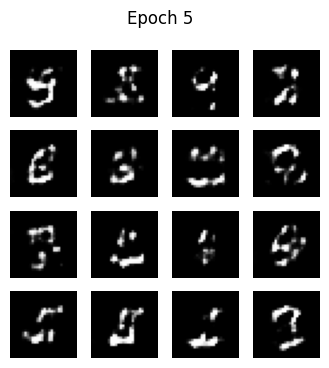

Epoch 6/20 | G Loss=0.8342 | D Loss=1.2581
Epoch 7/20 | G Loss=0.8739 | D Loss=1.2362
Epoch 8/20 | G Loss=0.8346 | D Loss=1.2686
Epoch 9/20 | G Loss=0.8321 | D Loss=1.2869
Epoch 10/20 | G Loss=0.7853 | D Loss=1.3158


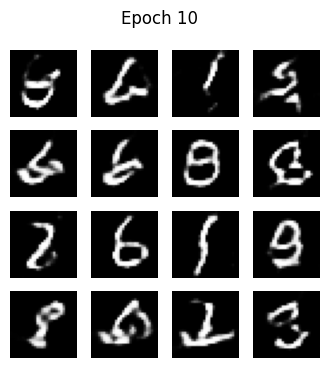

Epoch 11/20 | G Loss=0.8029 | D Loss=1.3101
Epoch 12/20 | G Loss=0.7717 | D Loss=1.3262
Epoch 13/20 | G Loss=0.7987 | D Loss=1.3139
Epoch 14/20 | G Loss=0.7721 | D Loss=1.3251
Epoch 15/20 | G Loss=0.7933 | D Loss=1.3153


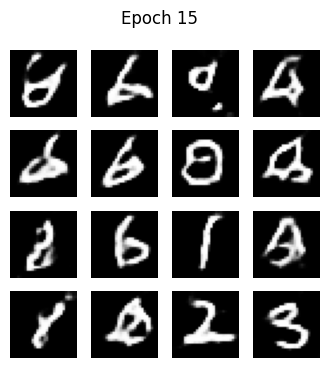

Epoch 16/20 | G Loss=0.7678 | D Loss=1.3266
Epoch 17/20 | G Loss=0.7784 | D Loss=1.3237
Epoch 18/20 | G Loss=0.8033 | D Loss=1.3062
Epoch 19/20 | G Loss=0.7908 | D Loss=1.3166
Epoch 20/20 | G Loss=0.7951 | D Loss=1.3084


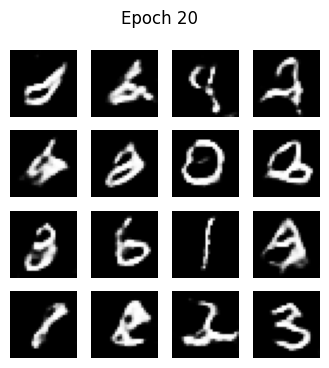

In [13]:
EPOCHS = 20

generator_losses = []
discriminator_losses = []

for epoch in range(EPOCHS):

    g_epoch_loss = []
    d_epoch_loss = []

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        g_epoch_loss.append(g_loss.numpy())
        d_epoch_loss.append(d_loss.numpy())

    generator_losses.append(
        np.mean(g_epoch_loss)
    )

    discriminator_losses.append(
        np.mean(d_epoch_loss)
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS}"
        f" | G Loss={generator_losses[-1]:.4f}"
        f" | D Loss={discriminator_losses[-1]:.4f}"
    )

    if (epoch + 1) % 5 == 0:
        generate_and_save_images(
            generator,
            epoch+1,
            seed
        )

## Step 13: Plot Loss Curves

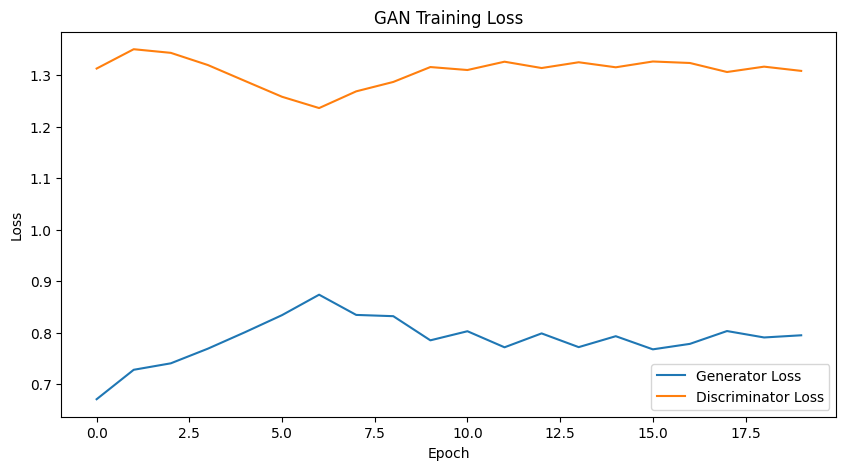

In [14]:
plt.figure(figsize=(10,5))

plt.plot(
    generator_losses,
    label="Generator Loss"
)

plt.plot(
    discriminator_losses,
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")

plt.legend()

plt.show()

## Step 14: Generate Final Digits

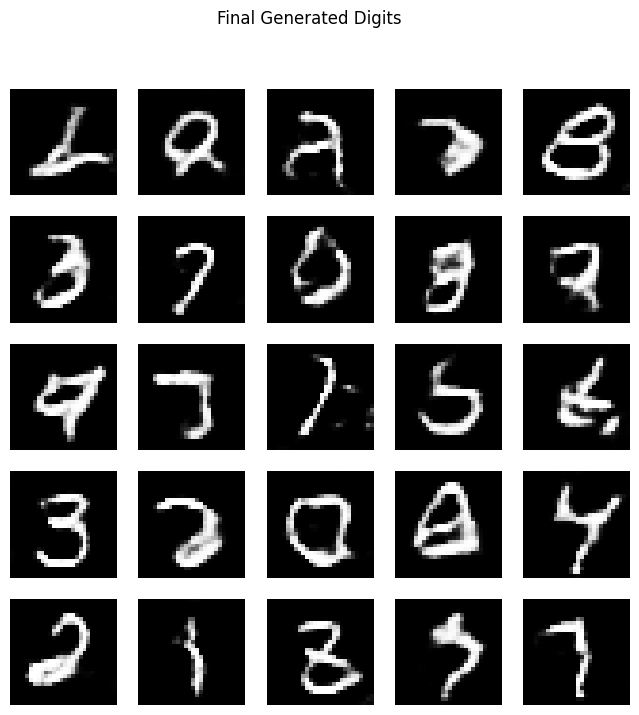

In [16]:
noise = tf.random.normal([25,100])

generated_images = generator(
    noise,
    training=False
)

plt.figure(figsize=(8,8))

for i in range(25):

    plt.subplot(5,5,i+1)

    plt.imshow(
        generated_images[i,:,:,0]*127.5+127.5,
        cmap='gray'
    )

    plt.axis('off')

plt.suptitle("Final Generated Digits")
plt.show()

Project Analysis

Observations

1. The Generator initially produces random noise images.
2. As training progresses, the Generator learns MNIST digit patterns.
3. The Discriminator becomes better at distinguishing real and fake images.
4. Both networks compete against each other through adversarial learning.
5. Generated images become clearer after approximately 15–20 epochs.

Challenges Faced

1. GAN training can be unstable.
2. Generator and Discriminator losses may fluctuate.
3. Mode collapse may occur if one network becomes too strong.

Results

* Successfully loaded and preprocessed MNIST dataset.
* Implemented Generator and Discriminator models.
* Trained GAN using Binary Cross Entropy loss.
* Generated synthetic handwritten digit images.
* Visualized generated samples and loss curves.

Conclusion

The GAN successfully learned the MNIST digit distribution and generated realistic handwritten digits. The project demonstrates the core principle of Generative AI, where the Generator and Discriminator improve simultaneously through adversarial learning.